**General instructions and tips:**
* Work with smaller subsets of data before processing the entire dataset.
* All data processing should be done via dask i.e., do not call `compute` then further process the resulting pandas dataframe. In the case of Problem 1, the data to be plotted should be the output of `compute`.
* Do **not** print or display large amount of results. You will get deductions if you make the browser unresponsive. 

# Problem 1 [20 pts]

Using KMeans, cluster into 5 clusters all NYC yellow taxi trips in 2010-2015 based on their pickup coordinates. The bounding box coordinates of NYC are [-74.2589, 40.4774, -73.7004, 40.9176] so only consider trips within this box. The data is at `/mnt/data/public/nyctaxi/all`. Plot the points colored by their label. You should get something like the figure below.

![NYC taxi pickup locations](nyctaxi-cluster.png)

**Hints**:
* The main challenge of this problem is in cleaning the data and transforming it to a form that can be used by KMeans.
* No need to display all of the points.
* Runtime of the final code is less than 10 mins.

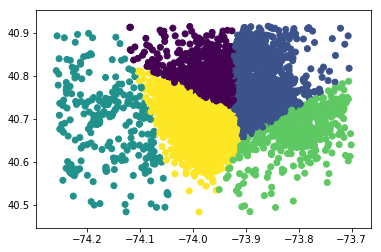

In [18]:
import dask.bag as db
import json
from dask.diagnostics import ProgressBar
import dask.dataframe as dd
import glob
from dask.delayed import delayed
import pandas as pd
from dask.distributed import Client

client = Client('192.168.212.2:31416')

pbar = ProgressBar()
pbar.register()
cols = ['vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count',
       'trip_distance', 'pickup_longitude', 'pickup_latitude', 'rate_code',
       'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude',
       'payment_type', 'fare_amount', 'surcharge', 'mta_tax', 'tip_amount',
       'tolls_amount', 'total_amount']
two_cols = ['pickup_longitude', 'pickup_latitude']
filenames = glob.glob('/mnt/data/public/nyctaxi/all/yellow_tripdata_201[0-5]*.csv',)
dfs = [delayed(pd.read_csv)(fn, delimiter=',', header=0
                             ,names = two_cols
                            , usecols =[5,6]
 #                           header = 0
                       ,      dtype = {'rate_code':object, 'store_and_fwd_flag':object,'fare_amount':object,
                'pickup_longitude':float, 'pickup_latitude':float} 
                          )
       for fn in filenames]
# delayed - creating a graph

taxi = dd.from_delayed(dfs)

taxi_sampled =taxi.sample(frac=0.001).persist()

taxi_filtered = (taxi_sampled[(taxi_sampled['pickup_longitude'] >= -74.2589 ) &
                      (taxi_sampled['pickup_latitude'] >= 40.4774) & 
                      (taxi_sampled['pickup_longitude'] <=  -73.7004) & 
                      (taxi_sampled['pickup_latitude'] <= 40.9176)].persist())

X_clust = (taxi_filtered.to_dask_array(lengths=True).persist())

kmeans = KMeans(5)
    
#with parallel_backend('dask'):
    #kmeans.fit(X_clust)
kmeans.fit(X_clust)
y_pred = kmeans.predict(X_clust).persist()

plt.scatter(X_clust[:,0].compute(), X_clust[:,1].compute(), c=y_pred)

In [2]:
import glob
import pandas as pd
import dask.dataframe as dd
from dask.diagnostics import ProgressBar
from dask.delayed import delayed
import os
from dask.distributed import Client
import zipfile
#client = Client('192.168.212.2:31416')
#client = Client('10.233.24.232:8786')
#client = Client('10.233.13.99:7077')


In [1]:
from dask.delayed import delayed

dfs = []
for every_file in files:
    archive = zipfile.ZipFile(filepath + every_file, 'r')
    contents = [x for x in archive.namelist() if 'csv' in x]
    dfs.append(delayed(pd.read_csv(archive.open(contents[0]), usecols=['time','cik'])))
df = dd.from_delayed(dfs) # df is a dask dataframe

NameError: name 'files' is not defined

# Problem 2 [20 pts]

Find the most requested [CIK (Central Index Key)](https://www.sec.gov/files/EDGAR_variables_FINAL.pdf), for each hour of day, in the [EDGAR filings website](https://www.sec.gov/dera/data/edgar-log-file-data-set.html) of the US SEC in the first quarter of 2016. The data can be found at `/mnt/data/public/edgar`. You should get something like the following:

<img src="most-requested-cik.png" width="125em" />

**Hints:**
* The [`zipfile`](https://docs.python.org/3/library/zipfile.html) module can be used to work with zip files.
* To create a file object to a compressed file `filename` inside a zip file with file path `file_path`, you may do the following: `zipfile.ZipFile(file_path).open(filename)`
* For additional patterns accepted by glob, see the [fnmatch](https://docs.python.org/3/library/fnmatch.html) documentation.
* You may find the [os.path](https://docs.python.org/3/library/os.path.html) module useful.
* You may need to set `meta='float'` somewhere.
* Bonus points if you can change the column name to `hour of day` without converting to a pandas dataframe first.
* Runtime of the final code is less than 20 minutes.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()

# Problem 3 [20 pts]

Find the mean hourly page views of the English Wikipedia (`en.z`) article `Philippines` (exact match) for every month in 2017. The data is at `/mnt/data/public/wikipedia/pageviews`. You will need the files whose filenames end with `views-ge-5.bz2`. The output should be sorted chronologically i.e., from January to December. You should get the output below.

<img src="mean-hourly-pageviews.png" width="200em" />

**Hints:**
* The data format of each file is described in the first few lines of each file.
* The encoding of the bzipped text files is `latin-1`.
* Go back to the definition of mean instead of naively calling the `mean` method.
* The month of year is extracted from the filename.
* Runtime of the final code is less than 20 mins.

In [ ]:
# YOUR CODE HERE
raise NotImplementedError()